<h3 style="color:white">Model Explainability Using SHAP</h3>

In [1]:
%pip install shap

   ---------------------------------------- 0.0/755.4 kB ? eta -:--:--
   ---------------------------------------- 0.0/755.4 kB ? eta -:--:--
   ---------------------------------------- 755.4/755.4 kB 4.1 MB/s  0:00:00

   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   ---------------------------------------- 2/2 [shap]

Note: you may need to restart the kernel to use updated packages.


<h3 style="color:white">Load Dataset and Trained Model</h3>

In [2]:
import pandas as pd
import joblib
import shap
import matplotlib.pyplot as plt

df = pd.read_csv("../data/processed/ChargingRecords_cleaned.csv")

rf_model = joblib.load(
    "../models/classification/random_forest_classifier.pkl"
)

print("Dataset shape:", df.shape)
print("Model loaded successfully!")
print("SHAP version:", shap.__version__)

Dataset shape: (72826, 13)
Model loaded successfully!
SHAP version: 0.53.0


<h3 style="color:white">Prepare Features for Explainability</h3>

In [3]:
# Create the target label using the same threshold as Notebook 04
threshold = df["Demand"].median()
df["Demand_Level"] = (df["Demand"] >= threshold).astype(int)

# Select the same input features used during classification
X = df[
    [
        "UserID",
        "ChargerID",
        "ChargerCompany",
        "Location",
        "ChargerType",
        "Duration"
    ]
]

# Convert Location into numerical columns
X = pd.get_dummies(X, columns=["Location"], dtype=int)

# Use a sample to make SHAP analysis faster
X_sample = X.sample(n=500, random_state=42)

print("Feature shape:", X.shape)
print("SHAP sample shape:", X_sample.shape)
print("Demand threshold:", threshold)
print("Features prepared successfully!")

Feature shape: (72826, 19)
SHAP sample shape: (500, 19)
Demand threshold: 14.1
Features prepared successfully!


<h3 style="color:white">Calculate SHAP Values</h3>

In [4]:
# Create a SHAP explainer for the Random Forest model
explainer = shap.TreeExplainer(rf_model)

# Calculate SHAP values for the sample
shap_values = explainer.shap_values(X_sample)

print("SHAP values calculated successfully!")
print("SHAP output type:", type(shap_values))

SHAP values calculated successfully!
SHAP output type: <class 'numpy.ndarray'>


<h3 style="color:white">SHAP Feature Importance</h3>

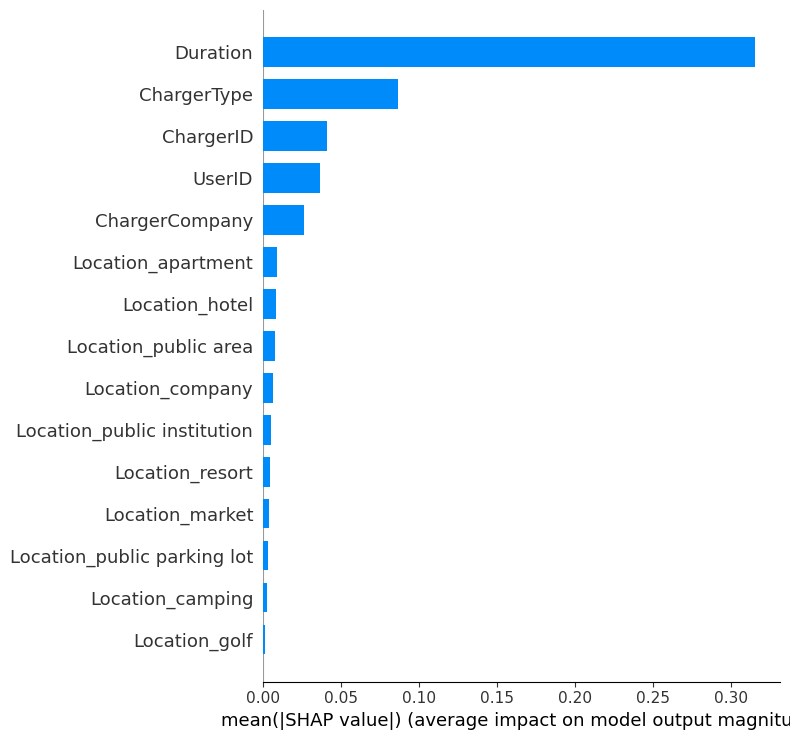

In [5]:
# Select SHAP values for the High Demand class
high_demand_shap = shap_values[:, :, 1]

# Display the most important features
shap.summary_plot(
    high_demand_shap,
    X_sample,
    plot_type="bar",
    max_display=15
)

<h3 style="color:white">SHAP Feature Impact Analysis</h3>

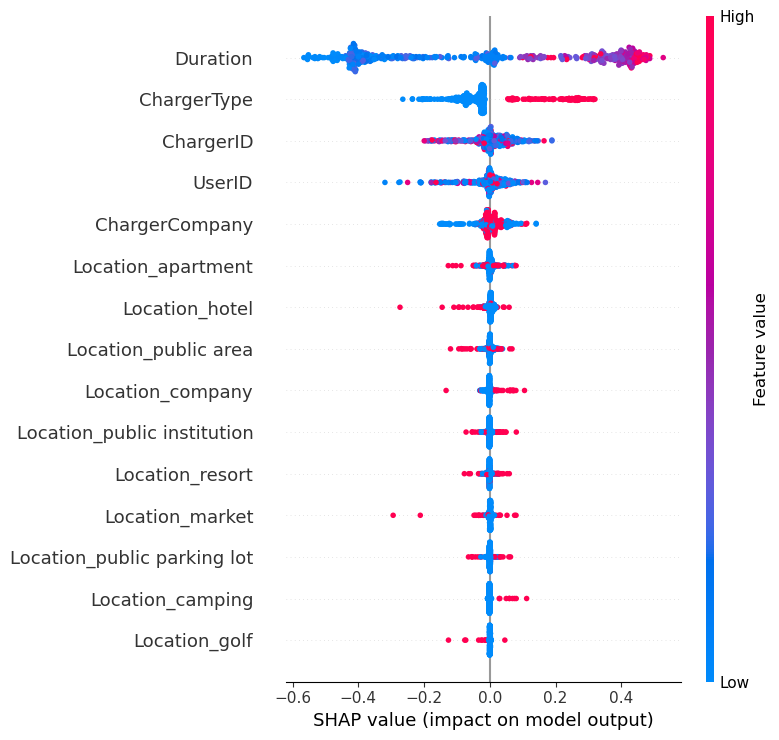

In [6]:
shap.summary_plot(
    shap_values[:, :, 1],
    X_sample,
    max_display=15
)

<h3 style="color:white">Save SHAP graph</h3>

In [7]:
import os
import matplotlib.pyplot as plt
import shap

os.makedirs("../reports/figures", exist_ok=True)

shap.summary_plot(
    shap_values[:, :, 1],
    X_sample,
    plot_type="bar",
    max_display=15,
    show=False
)

plt.savefig(
    "../reports/figures/shap_feature_importance.png",
    bbox_inches="tight",
    dpi=300
)

plt.close()
print("SHAP feature-importance graph saved successfully!")

SHAP feature-importance graph saved successfully!


<h3 style="color:white">SHAP Feature Impact Analysis (Beeswarm Plot)</h3>

In [8]:
shap.summary_plot(
    shap_values[:, :, 1],
    X_sample,
    max_display=15,
    show=False
)

plt.savefig(
    "../reports/figures/shap_beeswarm.png",
    bbox_inches="tight",
    dpi=300
)

plt.close()
print("SHAP beeswarm graph saved successfully!")

SHAP beeswarm graph saved successfully!


### LIME Explainability

In [9]:
%pip install lime

  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'done'
  Created wheel for lime: filename=lime-0.2.0.1-py3-none-any.whl size=283917 sha256=7122f92405ee3a2a06f12986373aa526847c56141b2d2651bffaf3027f39b967
  Stored in directory: c:\users\vishnupriyan\appdata\local\pip\cache\wheels\7c\04\5c\157dc9106512a6c7a30653ec064490c94a49e0fc8f63d19ab9
Successfully built lime
Note: you may need to restart the kernel to use updated packages.


In [10]:
import lime
print("LIME installed successfully!")

LIME installed successfully!


In [11]:
import pandas as pd
import joblib

df = pd.read_csv("../data/processed/ChargingRecords_cleaned.csv")

rf_model = joblib.load(
    "../models/classification/random_forest_classifier.pkl"
)

print("Dataset shape:", df.shape)
print("Random Forest model loaded successfully!")

Dataset shape: (72826, 13)
Random Forest model loaded successfully!


In [12]:
from lime.lime_tabular import LimeTabularExplainer

# Select the same features used during model training
X = df[
    [
        "UserID",
        "ChargerID",
        "ChargerCompany",
        "Location",
        "ChargerType",
        "Duration"
    ]
]

# Encode Location
X = pd.get_dummies(X, columns=["Location"], dtype=int)

# Match the model's training feature columns and order
X = X.reindex(
    columns=rf_model.feature_names_in_,
    fill_value=0
)

# Create LIME explainer
explainer = LimeTabularExplainer(
    training_data=X.to_numpy(),
    feature_names=X.columns.tolist(),
    class_names=["Normal Demand", "High Demand"],
    mode="classification",
    discretize_continuous=True,
    random_state=42
)

print("LIME explainer created successfully!")
print("Number of features:", X.shape[1])

LIME explainer created successfully!
Number of features: 19


In [13]:
from lime.lime_tabular import LimeTabularExplainer

# Select the same features used during model training
X = df[
    [
        "UserID",
        "ChargerID",
        "ChargerCompany",
        "Location",
        "ChargerType",
        "Duration"
    ]
]

# Encode Location
X = pd.get_dummies(X, columns=["Location"], dtype=int)

# Match the model's training feature columns and order
X = X.reindex(
    columns=rf_model.feature_names_in_,
    fill_value=0
)

# Create LIME explainer
explainer = LimeTabularExplainer(
    training_data=X.to_numpy(),
    feature_names=X.columns.tolist(),
    class_names=["Normal Demand", "High Demand"],
    mode="classification",
    discretize_continuous=True,
    random_state=42
)

print("LIME explainer created successfully!")
print("Number of features:", X.shape[1])

LIME explainer created successfully!
Number of features: 19


d:\anaconda_python\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


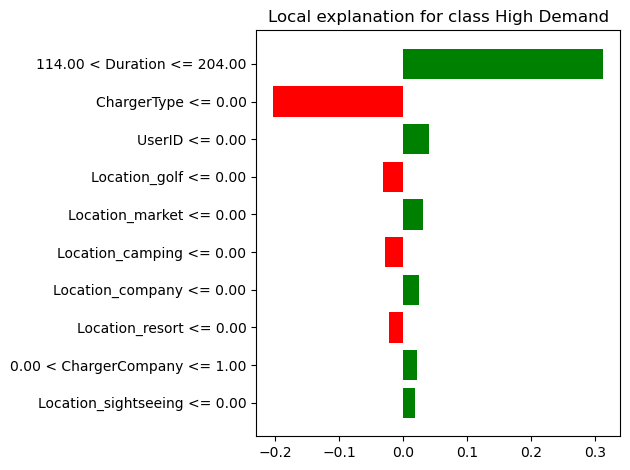

Actual demand: 20.36
Predicted class: High Demand
Prediction probabilities: [0.02 0.98]


d:\anaconda_python\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
d:\anaconda_python\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


In [14]:
import matplotlib.pyplot as plt

# Select one record to explain
sample_index = 0
sample = X.iloc[sample_index].to_numpy()

# Generate LIME explanation
lime_exp = explainer.explain_instance(
    data_row=sample,
    predict_fn=rf_model.predict_proba,
    num_features=10
)

# Display explanation chart
fig = lime_exp.as_pyplot_figure()
plt.tight_layout()
plt.show()

# Display prediction probabilities
print("Actual demand:", df.iloc[sample_index]["Demand"])
print(
    "Predicted class:",
    ["Normal Demand", "High Demand"][
        rf_model.predict(sample.reshape(1, -1))[0]
    ]
)
print(
    "Prediction probabilities:",
    rf_model.predict_proba(sample.reshape(1, -1))[0]
)

In [15]:
import os

os.makedirs("../reports/figures", exist_ok=True)

# Save interactive HTML explanation
lime_exp.save_to_file(
    "../reports/figures/lime_explanation.html"
)

# Save PNG chart
fig.savefig(
    "../reports/figures/lime_explanation.png",
    dpi=300,
    bbox_inches="tight"
)

print("LIME explanation saved successfully!")
print("HTML: reports/figures/lime_explanation.html")
print("PNG: reports/figures/lime_explanation.png")

LIME explanation saved successfully!
HTML: reports/figures/lime_explanation.html
PNG: reports/figures/lime_explanation.png
